# Experiment 12 · Customer Segmentation Using K-Means Clustering

Group 150 simulated shoppers by monthly visits and average spend per visit. Compare the groups to see which shoppers visit often or spend more per trip. The data are synthetic and the spending amounts are in rupees.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
customers, _ = make_blobs(
    n_samples=150, centers=[[3, 450], [12, 520], [6, 1400]],
    cluster_std=[0.85, 1.2, 0.95], random_state=42
)
# Add more realistic variation to spending and round visits to whole numbers.
rng = np.random.default_rng(42)
customers[:, 1] += rng.normal(0, 100, len(customers))
customers[:, 0] = np.maximum(1, np.round(customers[:, 0]))
print("Monthly visits and average spend per visit (Rs):")
print(customers[:5].round(1))

Monthly visits and average spend per visit (Rs):
[[  3.  481.3]
 [  3.  346.9]
 [ 10.  594.5]
 [ 11.  613.4]
 [ 12.  326.6]]


In [3]:
# Scale both columns so the rupee amounts do not dominate the distances.
scaler = StandardScaler()
scaled_customers = scaler.fit_transform(customers)

In [4]:
model = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = model.fit_predict(scaled_customers)
print("Silhouette score:", round(silhouette_score(scaled_customers, labels), 3))

Silhouette score: 0.829


In [5]:
# Convert the centers back to visits and rupees to interpret each group.
centers = scaler.inverse_transform(model.cluster_centers_)
for group, (visits, spend) in enumerate(centers):
    count = np.sum(labels == group)
    print(f"Group {group}: {count} shoppers, {visits:.1f} visits/month, Rs {spend:.0f} per visit")

Group 0: 50 shoppers, 11.9 visits/month, Rs 510 per visit
Group 1: 50 shoppers, 2.9 visits/month, Rs 439 per visit
Group 2: 50 shoppers, 6.1 visits/month, Rs 1406 per visit


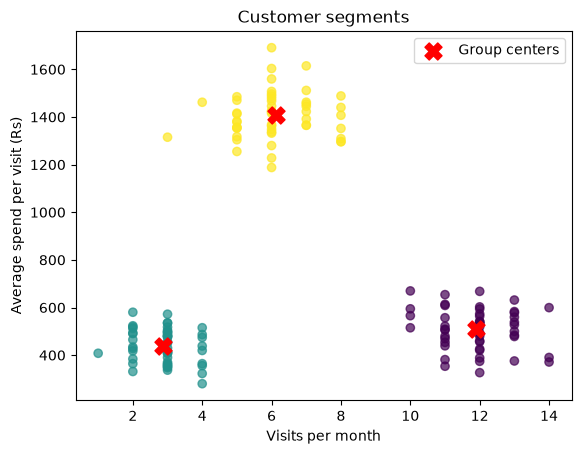

In [6]:
plt.scatter(customers[:, 0], customers[:, 1], c=labels, cmap="viridis", alpha=0.7)
plt.scatter(centers[:, 0], centers[:, 1], color="red", marker="X", s=150, label="Group centers")
plt.xlabel("Visits per month")
plt.ylabel("Average spend per visit (Rs)")
plt.title("Customer segments")
plt.legend()
plt.show()